In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# WT

## Load

In [3]:
rep0_wt_gmx=pd.read_csv('../../data/1bf5/wt/rep0/analysis/002.hbonds/hbonds_gmx_ext.csv')
rep0_wt_mda=pd.read_csv('../../data/1bf5/wt/rep0/analysis/002.hbonds/hbonds_mda_ext.csv')
rep1_wt_gmx=pd.read_csv('../../data/1bf5/wt/rep1/analysis/002.hbonds/hbonds_gmx_ext.csv')
rep1_wt_mda=pd.read_csv('../../data/1bf5/wt/rep1/analysis/002.hbonds/hbonds_mda_ext.csv')
rep2_wt_gmx=pd.read_csv('../../data/1bf5/wt/rep2/analysis/002.hbonds/hbonds_gmx_ext.csv')
rep2_wt_mda=pd.read_csv('../../data/1bf5/wt/rep2/analysis/002.hbonds/hbonds_mda_ext.csv')
rep3_wt_gmx=pd.read_csv('../../data/1bf5/wt/rep3/analysis/002.hbonds/hbonds_gmx_ext.csv')
rep3_wt_mda=pd.read_csv('../../data/1bf5/wt/rep3/analysis/002.hbonds/hbonds_mda_ext.csv')

dfs_wt = np.array([[rep0_wt_gmx, rep0_wt_mda], [rep1_wt_gmx, rep1_wt_mda], [rep2_wt_gmx, rep2_wt_mda], [rep3_wt_gmx, rep3_wt_mda]], dtype=object)

In [4]:
len(dfs_wt)

4

In [5]:
rep0_wt_gmx.columns

Index(['donor', 'hydrogen', 'acceptor', 'count', 'frame%', 'donor_res_name',
       'donor_res_num', 'donor_atom_name', 'donor_chain', 'acceptor_res_name',
       'acceptor_res_num', 'acceptor_atom_name', 'acceptor_chain',
       'donor_type', 'acceptor_type', 'donor_res_num_adjusted',
       'acceptor_res_num_adjusted', 'donor_section', 'acceptor_section'],
      dtype='object')

In [6]:
rep0_wt_mda.columns

Index(['donor', 'hydrogen', 'acceptor', 'count', 'frame%', 'donor_res_name',
       'donor_res_num', 'donor_atom_name', 'donor_chain', 'acceptor_res_name',
       'acceptor_res_num', 'acceptor_atom_name', 'acceptor_chain',
       'donor_type', 'acceptor_type', 'donor_res_num_adjusted',
       'acceptor_res_num_adjusted', 'donor_section', 'acceptor_section'],
      dtype='object')

In [7]:
rep0_wt_mda.head()

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section
0,3216,3217,19899,6,0.599401,THR,192,OG1,A,DG,12,OP1,D,protein,DNA,327,12,DBD,backbone
1,3216,3217,19900,930,92.907093,THR,192,OG1,A,DG,12,OP2,D,protein,DNA,327,12,DBD,backbone
2,3376,3377,19933,3,0.299700,LYS,201,NZ,A,DG,13,OP2,D,protein,DNA,336,13,DBD,backbone
3,3376,3378,19933,2,0.199800,LYS,201,NZ,A,DG,13,OP2,D,protein,DNA,336,13,DBD,backbone
4,3376,3378,19946,1,0.099900,LYS,201,NZ,A,DG,13,N7,D,protein,DNA,336,13,DBD,base


In [8]:
rep0_wt_gmx.shape

(138, 19)

## Method comparison (gmx vs mda)

In [9]:
key_cols = ['donor', 'hydrogen', 'acceptor']

for i in range(len(dfs_wt)):
    overlap1 = pd.merge(
        dfs_wt[i][0][key_cols],
        dfs_wt[i][1][key_cols],
        how='inner'
    )

    total_bonds = dfs_wt[i][0].shape[0] + dfs_wt[i][1].shape[0]
    ratio = len(overlap1) / total_bonds

    print(f"Replicate {i}")
    print(f"Number of overlapping hydrogen bonds: {len(overlap1)} out of {total_bonds}. Ratio: {ratio}")

Replicate 0
Number of overlapping hydrogen bonds: 121 out of 291. Ratio: 0.41580756013745707
Replicate 1
Number of overlapping hydrogen bonds: 160 out of 403. Ratio: 0.3970223325062035
Replicate 2
Number of overlapping hydrogen bonds: 203 out of 470. Ratio: 0.4319148936170213
Replicate 3
Number of overlapping hydrogen bonds: 196 out of 457. Ratio: 0.4288840262582057


In [10]:
key_cols = ['donor', 'hydrogen', 'acceptor']

for i in range(len(dfs_wt)):
    gmx_filtered = dfs_wt[i][0][key_cols][dfs_wt[i][0]['frame%'] > 10]
    mda_filtered = dfs_wt[i][1][key_cols][dfs_wt[i][1]['frame%'] > 10]

    overlap1 = pd.merge(
        gmx_filtered,
        mda_filtered,
        how='inner'
    )

    total_bonds = gmx_filtered.shape[0] + mda_filtered.shape[0]
    ratio = len(overlap1) / total_bonds

    print(f"Replicate {i}")
    print(f"Number of overlapping hydrogen bonds: {len(overlap1)} out of {total_bonds}. Ratio: {ratio}")

Replicate 0
Number of overlapping hydrogen bonds: 32 out of 73. Ratio: 0.4383561643835616
Replicate 1
Number of overlapping hydrogen bonds: 34 out of 88. Ratio: 0.38636363636363635
Replicate 2
Number of overlapping hydrogen bonds: 24 out of 60. Ratio: 0.4
Replicate 3
Number of overlapping hydrogen bonds: 30 out of 68. Ratio: 0.4411764705882353


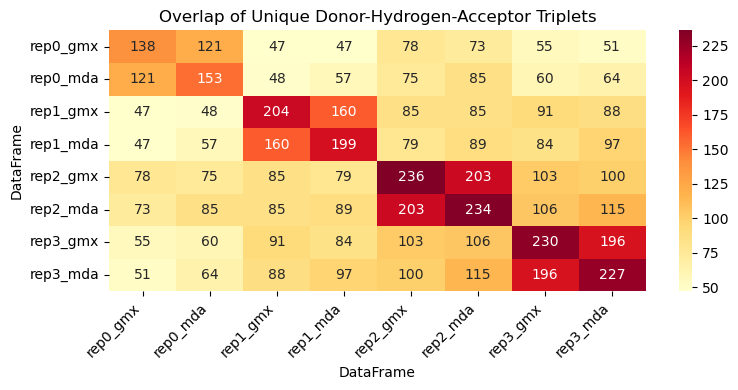

In [11]:
# List of all DataFrames with corresponding labels
dfs_wt = [rep0_wt_gmx, rep0_wt_mda, rep1_wt_gmx, rep1_wt_mda, rep2_wt_gmx, rep2_wt_mda, rep3_wt_gmx, rep3_wt_mda]
labels = ['rep0_gmx', 'rep0_mda', 'rep1_gmx', 'rep1_mda', 
          'rep2_gmx', 'rep2_mda', 'rep3_gmx', 'rep3_mda']

# Key columns for identifying unique triplets
key_cols = ['donor', 'hydrogen', 'acceptor']

# Create an 8x8 matrix to store overlap counts
overlap_matrix = np.zeros((8, 8))

# Calculate overlaps between each pair of DataFrames
for i in range(8):
    for j in range(8):
        # Get unique triplets from each DataFrame
        df1_triplets = dfs_wt[i][key_cols].drop_duplicates()
        df2_triplets = dfs_wt[j][key_cols].drop_duplicates()
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        # Store the count of overlapping triplets
        overlap_matrix[i, j] = len(overlap)

# Create heatmap
plt.figure(figsize=(8, 4))
sns.heatmap(overlap_matrix, 
            annot=True,  # Show numbers in cells
            fmt='.0f',   # Format numbers as integers
            cmap='YlOrRd',  # Color scheme
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap of Unique Donor-Hydrogen-Acceptor Triplets')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

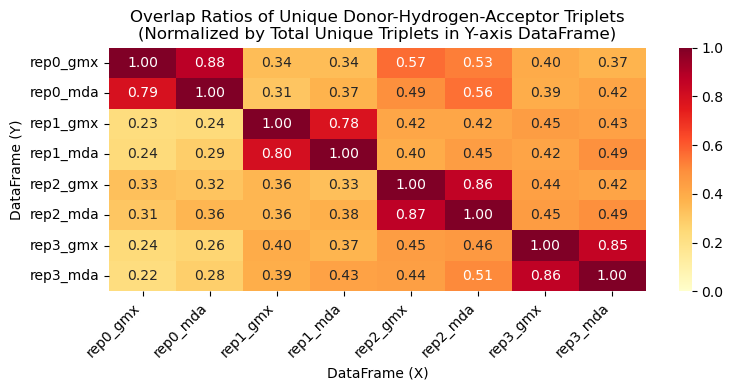

In [12]:
total_unique = [len(df[key_cols].drop_duplicates()) for df in dfs_wt]

# Create an 8x8 matrix to store overlap ratios
overlap_matrix = np.zeros((8, 8))

# Calculate overlaps as ratios between each pair of DataFrames
for i in range(8):
    for j in range(8):
        # Get unique triplets from each DataFrame
        df1_triplets = dfs_wt[i][key_cols].drop_duplicates()
        df2_triplets = dfs_wt[j][key_cols].drop_duplicates()
        
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        # Calculate ratio relative to total unique triplets in df[i] (y-axis)
        ratio = len(overlap) / total_unique[i] if total_unique[i] > 0 else 0
        overlap_matrix[i, j] = ratio

plt.figure(figsize=(8,4))
sns.heatmap(overlap_matrix, 
            annot=True,  # Show numbers in cells
            fmt='.2f',   # Format numbers to 2 decimal places
            cmap='YlOrRd',  # Color scheme
            xticklabels=labels,
            yticklabels=labels,
            vmin=0, vmax=1)  # Set color scale from 0 to 1

plt.title('Overlap Ratios of Unique Donor-Hydrogen-Acceptor Triplets\n'
          '(Normalized by Total Unique Triplets in Y-axis DataFrame)')
plt.xlabel('DataFrame (X)')
plt.ylabel('DataFrame (Y)')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

## Bond distribution

### Protein as donor

In [13]:
combined_df_wt = pd.concat(dfs_wt)
result_df = combined_df_wt.groupby(['donor', 'hydrogen', 'acceptor', 'donor_res_num_adjusted', 
                                 'acceptor_res_num_adjusted', 'acceptor_section'])['count'].sum().reset_index()

In [14]:
combined_df_wt.shape

(1621, 19)

In [15]:
combined_df_wt.sort_values('count', ascending=False).head()

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section
6,3392,3393,19081,1001,100.0000,THR,202,OG1,A,DT,9,OP2,C,protein,DNA,337,9,DBD,backbone
61,5365,5366,19049,1000,99.9001,SER,324,OG,A,DT,8,OP2,C,protein,DNA,459,8,DBD,backbone
42,5365,5366,19049,999,99.8002,SER,324,OG,A,DT,8,OP2,C,protein,DNA,459,8,DBD,backbone
118,14778,14779,19776,999,99.8002,SER,324,OG,B,DT,8,OP2,D,protein,DNA,459,8,DBD,backbone
5,3392,3393,19081,998,99.7003,THR,202,OG1,A,DT,9,OP2,C,protein,DNA,337,9,DBD,backbone


In [16]:
result_df.shape

(571, 7)

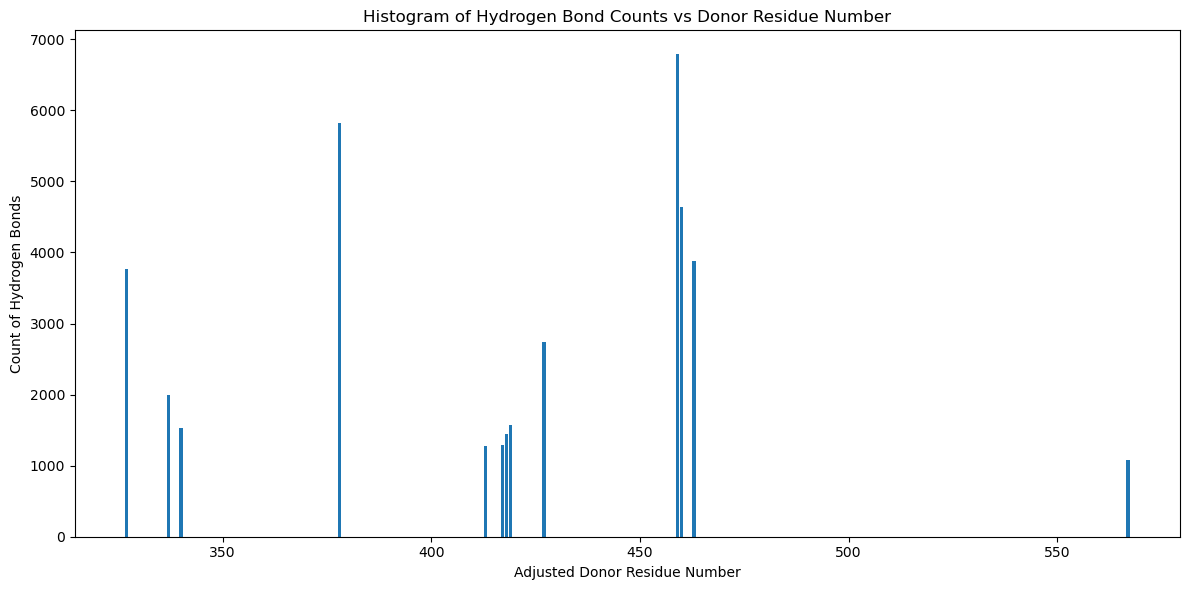

In [17]:
filtered_df = result_df[result_df['count'] > 1000]

plt.figure(figsize=(12, 6))
plt.bar(filtered_df['donor_res_num_adjusted'], filtered_df['count'])
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('Histogram of Hydrogen Bond Counts vs Donor Residue Number')
plt.tight_layout()

# Show the plot
plt.show()

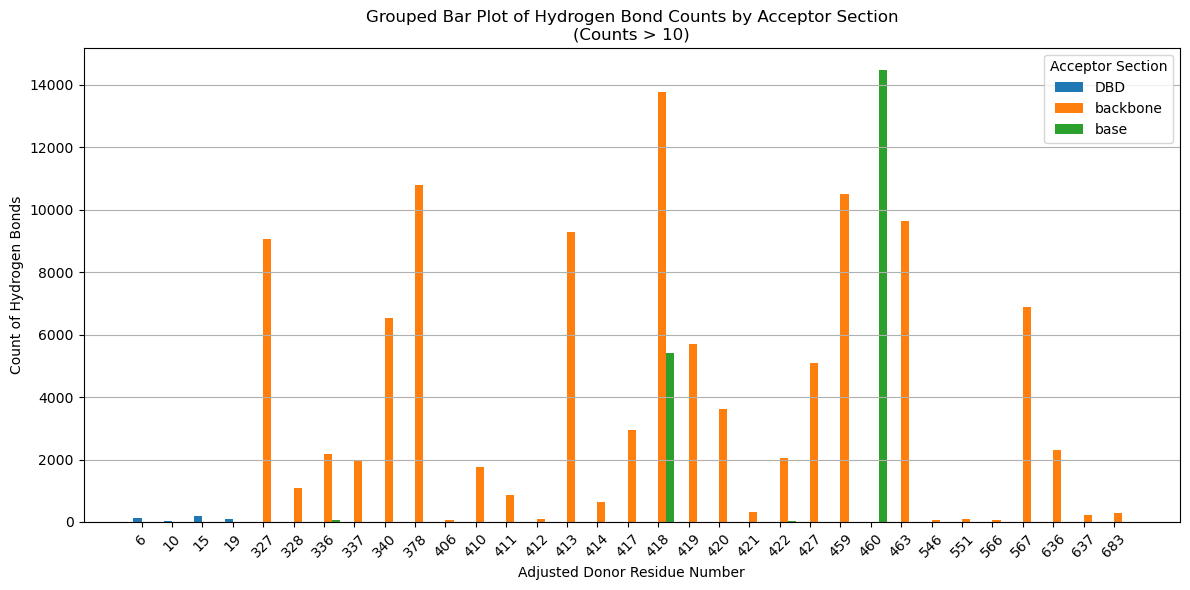

In [18]:
filtered_df = result_df[result_df['count'] > 10]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='acceptor_section',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('Grouped Bar Plot of Hydrogen Bond Counts by Acceptor Section\n(Counts > 10)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Acceptor Section')
plt.tight_layout()

# Show the plot
plt.show()

# T419R

## Load

In [29]:
rep1_T419R_gmx=pd.read_csv('../../data/1bf5/T419R/rep1/analysis/002.hbonds/hbonds_gmx_ext.csv')
rep1_T419R_mda=pd.read_csv('../../data/1bf5/T419R/rep1/analysis/002.hbonds/hbonds_mda_ext.csv')
rep2_T419R_gmx=pd.read_csv('../../data/1bf5/T419R/rep2/analysis/002.hbonds/hbonds_gmx_ext.csv')
rep2_T419R_mda=pd.read_csv('../../data/1bf5/T419R/rep2/analysis/002.hbonds/hbonds_mda_ext.csv')
rep3_T419R_gmx=pd.read_csv('../../data/1bf5/T419R/rep3/analysis/002.hbonds/hbonds_gmx_ext.csv')
rep3_T419R_mda=pd.read_csv('../../data/1bf5/T419R/rep3/analysis/002.hbonds/hbonds_mda_ext.csv')

dfs_T419R = [rep1_T419R_gmx, rep1_T419R_mda, rep2_T419R_gmx, rep2_T419R_mda, rep3_T419R_gmx, rep3_T419R_mda]

In [30]:
combined_df_T419R = pd.concat(dfs_T419R)

In [31]:
combined_df_T419R.sort_values('count', ascending=False).head()

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section
91,12639,12640,19192,1001,100.000000,THR,192,OG1,B,DC,12,OP1,C,protein,DNA,327,12,DBD,backbone
87,12639,12640,19192,1000,99.900100,THR,192,OG1,B,DC,12,OP1,C,protein,DNA,327,12,DBD,backbone
85,12639,12640,19192,1000,99.900100,THR,192,OG1,B,DC,12,OP1,C,protein,DNA,327,12,DBD,backbone
88,12639,12640,19192,997,99.600400,THR,192,OG1,B,DC,12,OP1,C,protein,DNA,327,12,DBD,backbone
11,4104,4105,19069,995,99.400599,ARG,243,NH1,A,DT,8,OP2,C,protein,DNA,378,8,DBD,backbone


## Bond distribution

In [32]:
result_df_T419R = combined_df_T419R.groupby(['donor', 'hydrogen', 'acceptor', 'donor_res_num_adjusted', 
                                 'acceptor_res_num_adjusted', 'acceptor_section'])['count'].sum().reset_index()

In [33]:
result_df_T419R.shape

(498, 7)

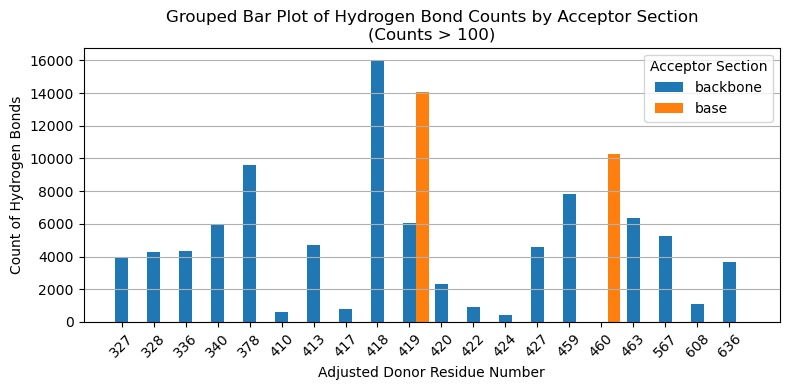

In [36]:
filtered_df = result_df_T419R[result_df_T419R['count'] > 100]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='acceptor_section',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(8, 4))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('Grouped Bar Plot of Hydrogen Bond Counts by Acceptor Section\n(Counts > 100)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Acceptor Section')
plt.tight_layout()

# Show the plot
plt.show()

## Comparison T419R vs WT
### Protein as donor

(array([143.,  12.,   2.,   4.,   4.,   5.,   3.,   0.,   2.,   8.]),
 array([ 0.0999001 ,  9.97002997, 19.84015984, 29.71028971, 39.58041958,
        49.45054945, 59.32067932, 69.19080919, 79.06093906, 88.93106893,
        98.8011988 ]),
 <BarContainer object of 10 artists>)

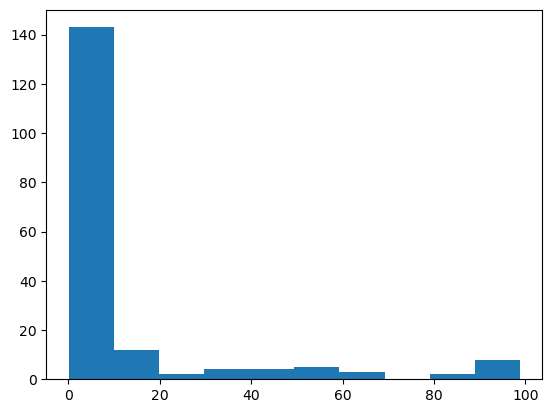

In [37]:
filtered_df = combined_df_T419R[combined_df_T419R['donor_res_num_adjusted'] == 419]
plt.hist(filtered_df['frame%'])

(array([14.,  2.,  4.,  0.,  1.,  2.,  0.,  2.,  1.,  2.]),
 array([ 0.0999001 ,  8.06193806, 16.02397602, 23.98601399, 31.94805195,
        39.91008991, 47.87212787, 55.83416583, 63.7962038 , 71.75824176,
        79.72027972]),
 <BarContainer object of 10 artists>)

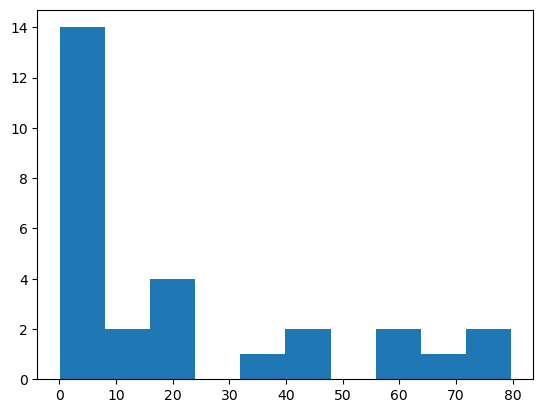

In [38]:
filtered_df = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == 419]
plt.hist(filtered_df['frame%'])

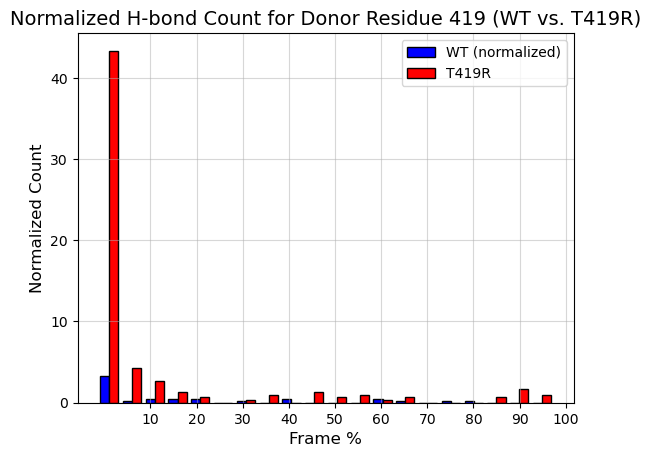

In [40]:
# Filter data
filtered_df_T419R = combined_df_T419R[combined_df_T419R['donor_res_num_adjusted'] == 419]
filtered_df_wt = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == 419]

# Common bins
bins = np.histogram(np.hstack((filtered_df_wt['frame%'], filtered_df_T419R['frame%'])), bins=20)[1]
wt_counts, wt_bins = np.histogram(filtered_df_wt['frame%'], bins=bins)
mut_counts, mut_bins = np.histogram(filtered_df_T419R['frame%'], bins=bins)

# Normalize counts by the number of replicates
normalized_wt_counts = wt_counts / 4
normalized_mut_counts = mut_counts / 3

# Bar positions
bar_width = (bins[1] - bins[0]) * 0.4
wt_positions = bins[:-1]
mut_positions = bins[:-1] + bar_width

# Plot
plt.bar(wt_positions, normalized_wt_counts, width=bar_width, color='blue', label='WT (normalized)', edgecolor='black')
plt.bar(mut_positions, normalized_mut_counts, width=bar_width, color='red', label='T419R', edgecolor='black')

# Customize
plt.xlabel('Frame %', fontsize=12)
plt.ylabel('Normalized Count', fontsize=12)  # Updated y-axis label
plt.title('Normalized H-bond Count for Donor Residue 419 (WT vs. T419R)', fontsize=14)  # Updated title
plt.xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
plt.legend(fontsize=10)
plt.grid(True, alpha=0.5)

plt.show()

In [41]:
filtered_df_T419R.shape

(183, 19)

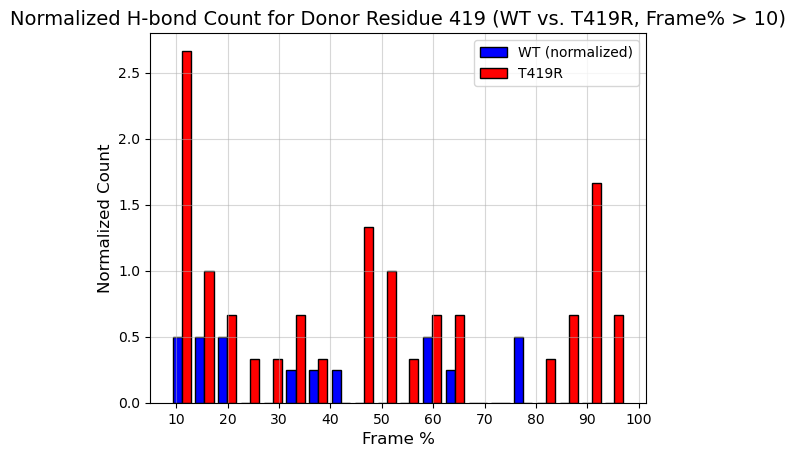

In [42]:
# Filter data for frame% > 10
filtered_df_T419R = combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == 419) & (combined_df_T419R['frame%'] > 10)]
filtered_df_wt = combined_df_wt[(combined_df_wt['donor_res_num_adjusted'] == 419) & (combined_df_wt['frame%'] > 10)]

# Common bins
bins = np.histogram(np.hstack((filtered_df_wt['frame%'], filtered_df_T419R['frame%'])), bins=20)[1]
wt_counts, wt_bins = np.histogram(filtered_df_wt['frame%'], bins=bins)
mut_counts, mut_bins = np.histogram(filtered_df_T419R['frame%'], bins=bins)

# Normalize counts by the number of replicates
normalized_wt_counts = wt_counts / 4
normalized_mut_counts = mut_counts / 3

# Bar positions
bar_width = (bins[1] - bins[0]) * 0.4
wt_positions = bins[:-1]
mut_positions = bins[:-1] + bar_width

# Plot
plt.bar(wt_positions, normalized_wt_counts, width=bar_width, color='blue', label='WT (normalized)', edgecolor='black')
plt.bar(mut_positions, normalized_mut_counts, width=bar_width, color='red', label='T419R', edgecolor='black')

# Customize
plt.xlabel('Frame %', fontsize=12)
plt.ylabel('Normalized Count', fontsize=12)  # Updated y-axis label
plt.title('Normalized H-bond Count for Donor Residue 419 (WT vs. T419R, Frame% > 10)', fontsize=14)  # Updated title
plt.xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
plt.legend(fontsize=10)
plt.grid(True, alpha=0.5)

plt.show()

In [44]:
filtered_df_T419R.shape

(6, 19)

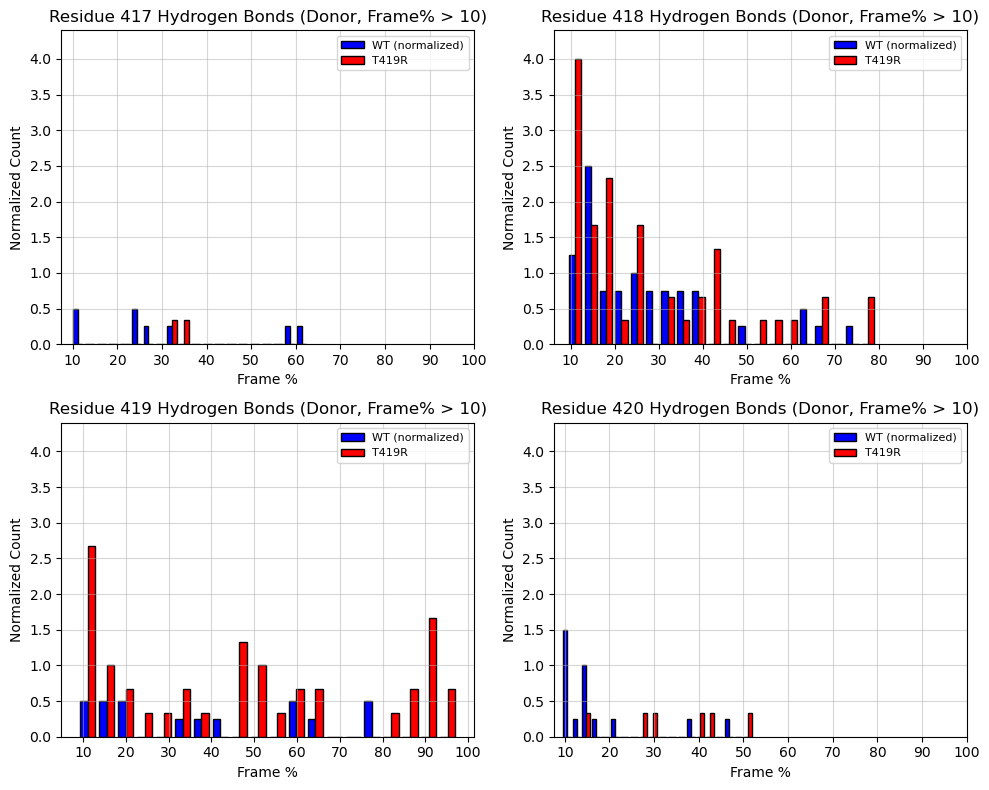

In [45]:

# Residues to plot
residues = [417, 418, 419, 420]

# Initialize a variable to track the maximum y-value
max_y_value = 0

# First pass: Calculate the maximum y-value across all residues
for residue in residues:
    # Filter data for the current residue and frame% > 10
    filtered_df_T419R = combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == residue) & (combined_df_T419R['frame%'] > 10)]
    filtered_df_wt = combined_df_wt[(combined_df_wt['donor_res_num_adjusted'] == residue) & (combined_df_wt['frame%'] > 10)]

    # Common bins
    bins = np.histogram(np.hstack((filtered_df_wt['frame%'], filtered_df_T419R['frame%'])), bins=20)[1]
    wt_counts, _ = np.histogram(filtered_df_wt['frame%'], bins=bins)
    mut_counts, _ = np.histogram(filtered_df_T419R['frame%'], bins=bins)

    # Normalize counts by the number of replicates
    normalized_wt_counts = wt_counts / 4
    normalized_mut_counts = mut_counts / 3

    # Update the maximum y-value
    max_y_value = max(max_y_value, max(normalized_wt_counts), max(normalized_mut_counts))

# Second pass: Plot the data
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()  # Flatten the 2D array of axes for easier indexing

for i, residue in enumerate(residues):
    # Filter data for the current residue and frame% > 10
    filtered_df_T419R = combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == residue) & (combined_df_T419R['frame%'] > 10)]
    filtered_df_wt = combined_df_wt[(combined_df_wt['donor_res_num_adjusted'] == residue) & (combined_df_wt['frame%'] > 10)]

    # Common bins
    bins = np.histogram(np.hstack((filtered_df_wt['frame%'], filtered_df_T419R['frame%'])), bins=20)[1]
    wt_counts, _ = np.histogram(filtered_df_wt['frame%'], bins=bins)
    mut_counts, _ = np.histogram(filtered_df_T419R['frame%'], bins=bins)

    # Normalize counts by the number of replicates
    normalized_wt_counts = wt_counts / 4
    normalized_mut_counts = mut_counts / 3

    # Bar positions
    bar_width = (bins[1] - bins[0]) * 0.4
    wt_positions = bins[:-1]
    mut_positions = bins[:-1] + bar_width

    # Plot on the current subplot
    axes[i].bar(wt_positions, normalized_wt_counts, width=bar_width, color='blue', label='WT (normalized)', edgecolor='black')
    axes[i].bar(mut_positions, normalized_mut_counts, width=bar_width, color='red', label='T419R', edgecolor='black')

    # Customize the subplot
    axes[i].set_xlabel('Frame %', fontsize=10)
    axes[i].set_ylabel('Normalized Count', fontsize=10)
    axes[i].set_title(f'Residue {residue} Hydrogen Bonds (Donor, Frame% > 10)', fontsize=12)
    axes[i].set_xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
    axes[i].set_ylim(0, max_y_value * 1.1)  # Use the same y-axis range for all plots
    axes[i].grid(True, alpha=0.5)
    axes[i].legend(fontsize=8)

# Remove any unused subplot (if fewer than 6 residues)
for j in range(len(residues), len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.show()

In [46]:
combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == 417) & (combined_df_T419R['frame%'] > 10)]

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section
117,14141,14142,19449,324,32.367632,THR,282,OG1,B,DC,20,OP1,C,protein,DNA,417,20,DBD,backbone
120,14141,14142,19449,346,34.565435,THR,282,OG1,B,DC,20,OP1,C,protein,DNA,417,20,DBD,backbone


In [48]:
combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == 419) & (combined_df_T419R['frame%'] > 10)].shape

(40, 19)

In [49]:
combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == 419) & (combined_df_T419R['frame%'] > 10)].sort_values('frame%', ascending=False)

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section
156,14169,14170,19449,989,98.801199,ARG,284,N,B,DC,20,OP1,C,protein,DNA,419,20,DBD,backbone
52,4765,4767,20168,972,97.102897,ARG,284,NH2,A,DT,19,O2,D,protein,DNA,419,19,DBD,base
56,4765,4767,20168,944,94.305694,ARG,284,NH2,A,DT,19,O2,D,protein,DNA,419,19,DBD,base
151,14185,14187,19408,924,92.307692,ARG,284,NH1,B,DT,18,O2,C,protein,DNA,419,18,DBD,base
53,4765,4766,20184,920,91.908092,ARG,284,NH2,A,DG,20,O4',D,protein,DNA,419,20,DBD,backbone
58,4765,4767,20168,913,91.208791,ARG,284,NH2,A,DT,19,O2,D,protein,DNA,419,19,DBD,base
49,4762,4763,20168,910,90.909091,ARG,284,NH1,A,DT,19,O2,D,protein,DNA,419,19,DBD,base
162,14188,14190,19408,895,89.410589,ARG,284,NH2,B,DT,18,O2,C,protein,DNA,419,18,DBD,base
151,14185,14187,19408,878,87.712288,ARG,284,NH1,B,DT,18,O2,C,protein,DNA,419,18,DBD,base
61,4765,4767,20168,845,84.415584,ARG,284,NH2,A,DT,19,O2,D,protein,DNA,419,19,DBD,base


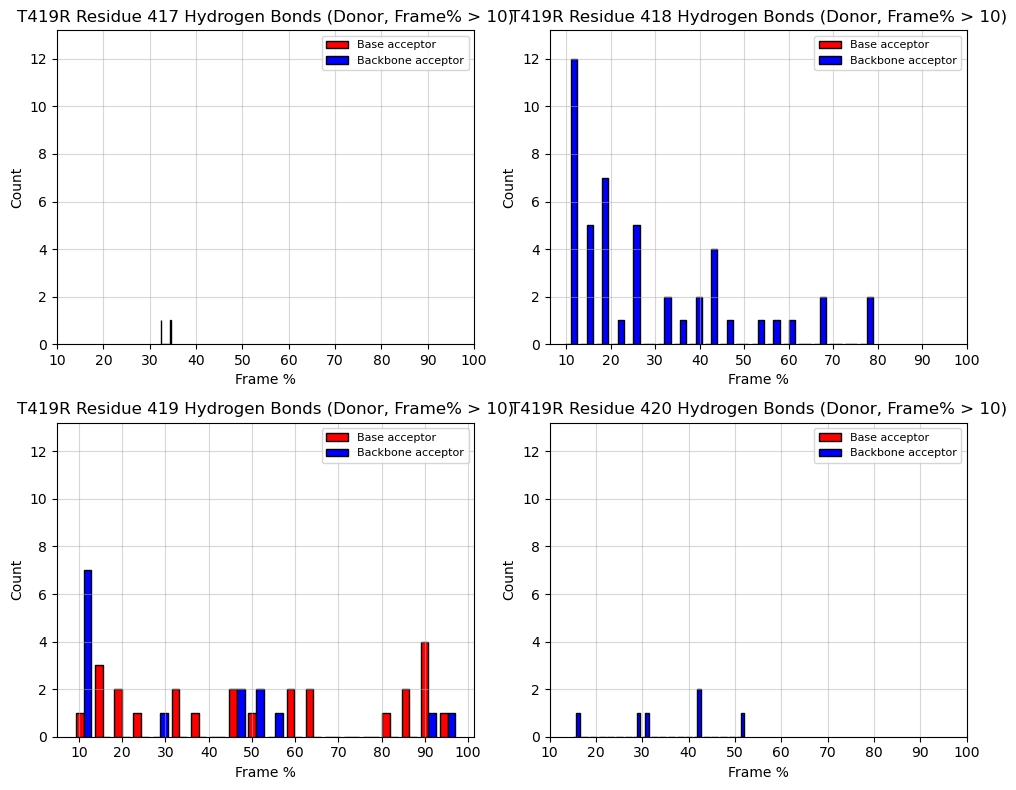

In [50]:
# Residues to plot
residues = [417, 418, 419, 420]

# Initialize a variable to track the maximum y-value
max_y_value = 0

# First pass: Calculate the maximum y-value across all residues
for residue in residues:
    # Filter mutant data for the current residue and frame% > 10
    filtered_df_T419R = combined_df_T419R[
        (combined_df_T419R['donor_res_num_adjusted'] == residue) & 
        (combined_df_T419R['frame%'] > 10)
    ]

    # Separate mutant data by acceptor_section
    mut_base = filtered_df_T419R[filtered_df_T419R['acceptor_section'] == 'base']
    mut_backbone = filtered_df_T419R[filtered_df_T419R['acceptor_section'] == 'backbone']

    # Common bins
    bins = np.histogram(np.hstack((mut_base['frame%'], mut_backbone['frame%'])), bins=20)[1]
    mut_base_counts, _ = np.histogram(mut_base['frame%'], bins=bins)
    mut_backbone_counts, _ = np.histogram(mut_backbone['frame%'], bins=bins)

    # Update the maximum y-value
    max_y_value = max(max_y_value, max(mut_base_counts), max(mut_backbone_counts))

# Second pass: Plot the data
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()  # Flatten the 2D array of axes for easier indexing

for i, residue in enumerate(residues):
    # Filter mutant data for the current residue and frame% > 10
    filtered_df_T419R = combined_df_T419R[
        (combined_df_T419R['donor_res_num_adjusted'] == residue) & 
        (combined_df_T419R['frame%'] > 10)
    ]

    # Separate mutant data by acceptor_section
    mut_base = filtered_df_T419R[filtered_df_T419R['acceptor_section'] == 'base']
    mut_backbone = filtered_df_T419R[filtered_df_T419R['acceptor_section'] == 'backbone']

    # Common bins
    bins = np.histogram(np.hstack((mut_base['frame%'], mut_backbone['frame%'])), bins=20)[1]
    mut_base_counts, _ = np.histogram(mut_base['frame%'], bins=bins)
    mut_backbone_counts, _ = np.histogram(mut_backbone['frame%'], bins=bins)

    # Bar positions
    bar_width = (bins[1] - bins[0]) * 0.4
    mut_base_positions = bins[:-1]
    mut_backbone_positions = bins[:-1] + bar_width

    # Plot on the current subplot
    axes[i].bar(mut_base_positions, mut_base_counts, width=bar_width, color='red', label='Base acceptor', edgecolor='black')
    axes[i].bar(mut_backbone_positions, mut_backbone_counts, width=bar_width, color='blue', label='Backbone acceptor', edgecolor='black')

    # Customize the subplot
    axes[i].set_xlabel('Frame %', fontsize=10)
    axes[i].set_ylabel('Count', fontsize=10)
    axes[i].set_title(f'T419R Residue {residue} Hydrogen Bonds (Donor, Frame% > 10)', fontsize=12)
    axes[i].set_xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
    axes[i].set_ylim(0, max_y_value * 1.1)  # Use the same y-axis range for all plots
    axes[i].grid(True, alpha=0.5)
    axes[i].legend(fontsize=8)

# Remove any unused subplot (if fewer than 4 residues)
for j in range(len(residues), len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.show()

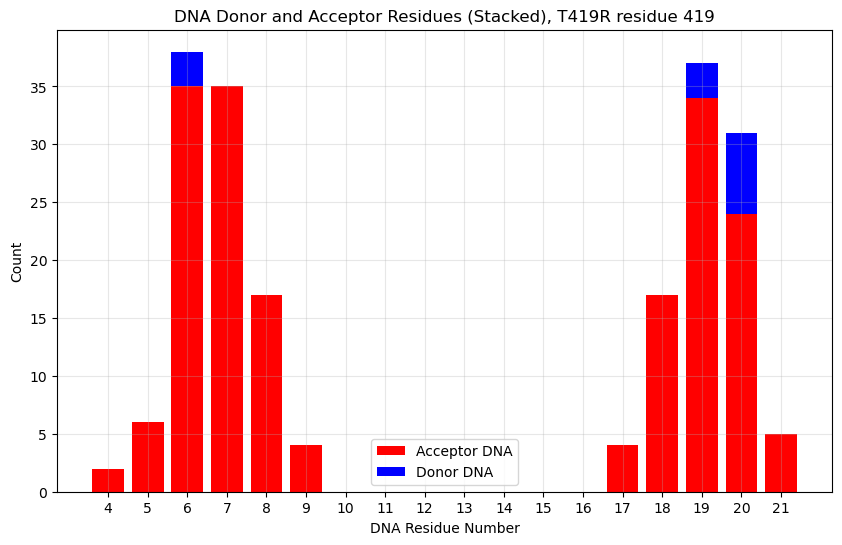

In [51]:
donor_T419R = combined_df_T419R[combined_df_T419R['donor_res_num_adjusted'] == 419]
acceptor_T419R = combined_df_T419R[combined_df_T419R['acceptor_res_num_adjusted'] == 419]

donor_counts = donor_T419R['acceptor_res_num_adjusted'].value_counts().sort_index()
acceptor_counts = acceptor_T419R['donor_res_num_adjusted'].value_counts().sort_index()

plt.figure(figsize=(10, 6))

# Get all unique residue numbers
all_res_nums = sorted(set(donor_counts.index).union(acceptor_counts.index))

# Align the counts, filling with 0 where no data exists
donor_values = [donor_counts.get(num, 0) for num in all_res_nums]
acceptor_values = [acceptor_counts.get(num, 0) for num in all_res_nums]

# Create stacked bar plot
plt.bar(all_res_nums, donor_values, color='red', label='Acceptor DNA')
plt.bar(all_res_nums, acceptor_values, bottom=donor_values, color='blue', label='Donor DNA')

# Set x-ticks for every unit
min_residue = min(all_res_nums)
max_residue = max(all_res_nums)
plt.xticks(range(int(min_residue), int(max_residue) + 1, 1))

plt.xlabel('DNA Residue Number')
plt.ylabel('Count')
plt.title('DNA Donor and Acceptor Residues (Stacked), T419R residue 419')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


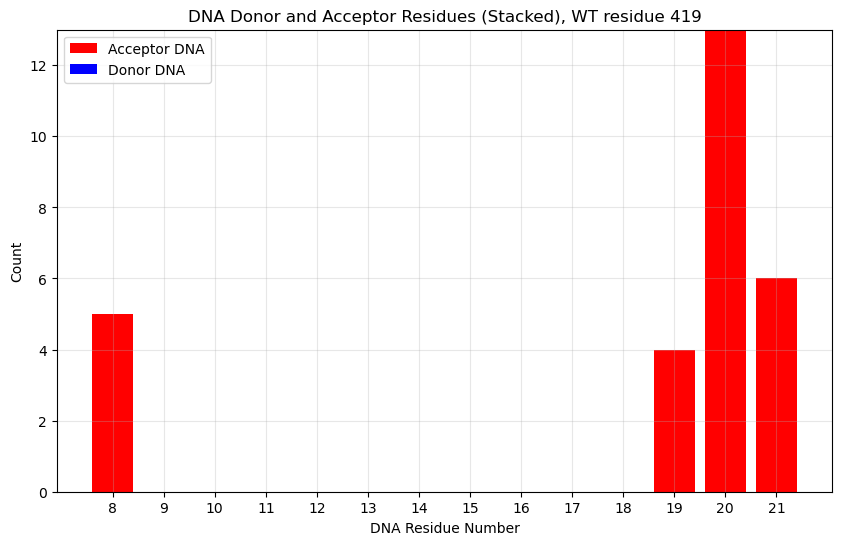

In [52]:
donor_T419R = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == 419]
acceptor_T419R = combined_df_wt[combined_df_wt['acceptor_res_num_adjusted'] == 419]

donor_counts = donor_T419R['acceptor_res_num_adjusted'].value_counts().sort_index()
acceptor_counts = acceptor_T419R['donor_res_num_adjusted'].value_counts().sort_index()

plt.figure(figsize=(10, 6))

# Get all unique residue numbers
all_res_nums = sorted(set(donor_counts.index).union(acceptor_counts.index))

# Align the counts, filling with 0 where no data exists
donor_values = [donor_counts.get(num, 0) for num in all_res_nums]
acceptor_values = [acceptor_counts.get(num, 0) for num in all_res_nums]

# Create stacked bar plot
plt.bar(all_res_nums, donor_values, color='red', label='Acceptor DNA')
plt.bar(all_res_nums, acceptor_values, bottom=donor_values, color='blue', label='Donor DNA')

# Set x-ticks for every unit
min_residue = min(all_res_nums)
max_residue = max(all_res_nums)
plt.xticks(range(int(min_residue), int(max_residue) + 1, 1))

plt.xlabel('DNA Residue Number')
plt.ylabel('Count')
plt.title('DNA Donor and Acceptor Residues (Stacked), WT residue 419')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

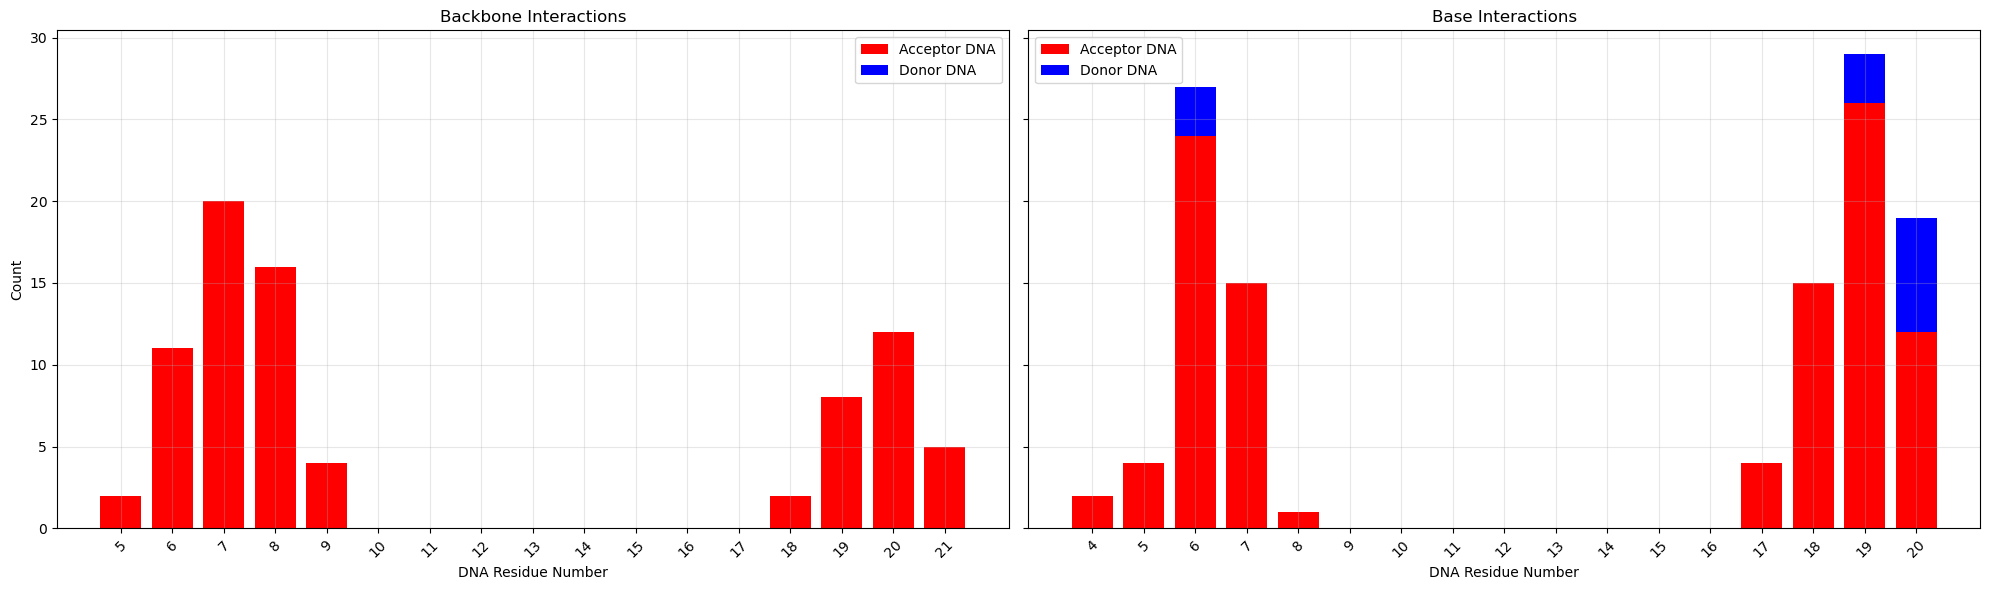

In [53]:
# Filter data for residue 419
donor_T419R = combined_df_T419R[combined_df_T419R['donor_res_num_adjusted'] == 419]
acceptor_T419R = combined_df_T419R[combined_df_T419R['acceptor_res_num_adjusted'] == 419]

# Create figure with two subplots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6), sharey=True)

# --- Backbone Plot ---
# Filter for backbone
donor_backbone = donor_T419R[donor_T419R['acceptor_section'] == 'backbone']
acceptor_backbone = acceptor_T419R[acceptor_T419R['donor_section'] == 'backbone']

donor_counts_backbone = donor_backbone['acceptor_res_num_adjusted'].value_counts().sort_index()
acceptor_counts_backbone = acceptor_backbone['donor_res_num_adjusted'].value_counts().sort_index()

# Get all unique residue numbers for backbone
all_res_nums_backbone = sorted(set(donor_counts_backbone.index).union(acceptor_counts_backbone.index))

# Align counts for backbone
donor_values_backbone = [donor_counts_backbone.get(num, 0) for num in all_res_nums_backbone]
acceptor_values_backbone = [acceptor_counts_backbone.get(num, 0) for num in all_res_nums_backbone]

# Create stacked bar plot for backbone
ax1.bar(all_res_nums_backbone, donor_values_backbone, color='red', label='Acceptor DNA')
ax1.bar(all_res_nums_backbone, acceptor_values_backbone, bottom=donor_values_backbone, 
        color='blue', label='Donor DNA')

# Set x-ticks for backbone
min_residue_backbone = min(all_res_nums_backbone)
max_residue_backbone = max(all_res_nums_backbone)
ax1.set_xticks(range(int(min_residue_backbone), int(max_residue_backbone) + 1, 1))
ax1.tick_params(axis='x', rotation=45)

ax1.set_xlabel('DNA Residue Number')
ax1.set_ylabel('Count')
ax1.set_title('Backbone Interactions')
ax1.grid(True, alpha=0.3)
ax1.legend()

# --- Base Plot ---
# Filter for base
donor_base = donor_T419R[donor_T419R['acceptor_section'] == 'base']
acceptor_base = acceptor_T419R[acceptor_T419R['donor_section'] == 'base']

donor_counts_base = donor_base['acceptor_res_num_adjusted'].value_counts().sort_index()
acceptor_counts_base = acceptor_base['donor_res_num_adjusted'].value_counts().sort_index()

# Get all unique residue numbers for base
all_res_nums_base = sorted(set(donor_counts_base.index).union(acceptor_counts_base.index))

# Align counts for base
donor_values_base = [donor_counts_base.get(num, 0) for num in all_res_nums_base]
acceptor_values_base = [acceptor_counts_base.get(num, 0) for num in all_res_nums_base]

# Create stacked bar plot for base
ax2.bar(all_res_nums_base, donor_values_base, color='red', label='Acceptor DNA')
ax2.bar(all_res_nums_base, acceptor_values_base, bottom=donor_values_base, 
        color='blue', label='Donor DNA')

# Set x-ticks for base
min_residue_base = min(all_res_nums_base)
max_residue_base = max(all_res_nums_base)
ax2.set_xticks(range(int(min_residue_base), int(max_residue_base) + 1, 1))
ax2.tick_params(axis='x', rotation=45)

ax2.set_xlabel('DNA Residue Number')
ax2.set_title('Base Interactions')
ax2.grid(True, alpha=0.3)
ax2.legend()

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

### Protein as acceptor

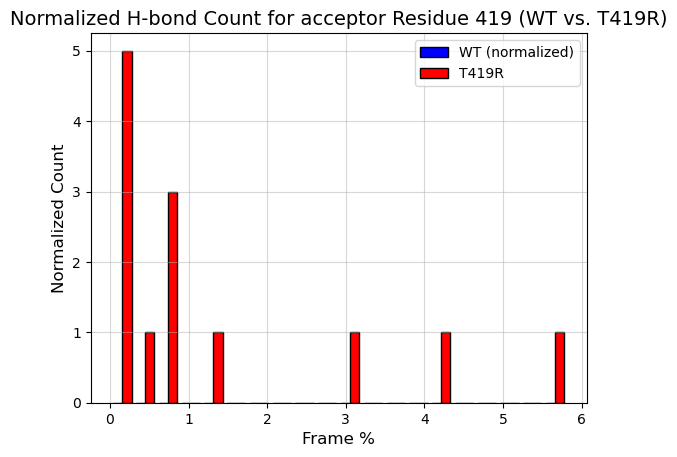

In [55]:
# Filter data
filtered_df_T419R = combined_df_T419R[combined_df_T419R['acceptor_res_num_adjusted'] == 419]
filtered_df_wt = combined_df_wt[combined_df_wt['acceptor_res_num_adjusted'] == 419]

# Common bins
bins = np.histogram(np.hstack((filtered_df_wt['frame%'], filtered_df_T419R['frame%'])), bins=20)[1]
wt_counts, wt_bins = np.histogram(filtered_df_wt['frame%'], bins=bins)
mut_counts, mut_bins = np.histogram(filtered_df_T419R['frame%'], bins=bins)

# Normalize WT counts by the number of replicates
normalized_wt_counts = wt_counts / 2

# Bar positions
bar_width = (bins[1] - bins[0]) * 0.4
wt_positions = bins[:-1]
mut_positions = bins[:-1] + bar_width

# Plot
plt.bar(wt_positions, normalized_wt_counts, width=bar_width, color='blue', label='WT (normalized)', edgecolor='black')
plt.bar(mut_positions, mut_counts, width=bar_width, color='red', label='T419R', edgecolor='black')

# Customize
plt.xlabel('Frame %', fontsize=12)
plt.ylabel('Normalized Count', fontsize=12)  # Updated y-axis label
plt.title('Normalized H-bond Count for acceptor Residue 419 (WT vs. T419R)', fontsize=14)  # Updated title
#plt.xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
plt.legend(fontsize=10)
plt.grid(True, alpha=0.5)

plt.show()

In [56]:
filtered_df_T419R.sort_values('frame%', ascending=False)

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section
218,20197,20199,4762,59,5.894106,DG,20,N2,D,ARG,284,NH1,A,DNA,protein,20,419,base,DBD
211,20197,20199,4765,42,4.195804,DG,20,N2,D,ARG,284,NH2,A,DNA,protein,20,419,base,DBD
198,19024,19026,4762,31,3.096903,DG,6,N2,C,ARG,284,NH1,A,DNA,protein,6,419,base,DBD
215,19437,19439,14188,15,1.498501,DG,19,N2,C,ARG,284,NH2,B,DNA,protein,19,419,base,DBD
212,19024,19026,4765,9,0.899101,DG,6,N2,C,ARG,284,NH2,A,DNA,protein,6,419,base,DBD
226,20197,20199,4762,9,0.899101,DG,20,N2,D,ARG,284,NH1,A,DNA,protein,20,419,base,DBD
209,20197,20199,4765,8,0.799201,DG,20,N2,D,ARG,284,NH2,A,DNA,protein,20,419,base,DBD
209,20197,20199,4759,6,0.599401,DG,20,N2,D,ARG,284,NE,A,DNA,protein,20,419,base,DBD
204,19024,19026,4762,2,0.199800,DG,6,N2,C,ARG,284,NH1,A,DNA,protein,6,419,base,DBD
210,20197,20199,4762,1,0.099900,DG,20,N2,D,ARG,284,NH1,A,DNA,protein,20,419,base,DBD


In [57]:
filtered_df_wt.sort_values('frame%', ascending=False)

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section


### Statistical test (Mann-Whitney)

In [58]:
# Load WT data (4 replicates, 2 methods each)
wt_dfs = []
for rep in range(0, 4):
    gmx_df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/002.hbonds/hbonds_gmx_ext.csv')
    mda_df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/002.hbonds/hbonds_mda_ext.csv')
    combined_rep = pd.concat([gmx_df, mda_df])
    wt_dfs.append(combined_rep)

# Load MUT data (1 replicate, 2 methods)
rep1_T419R_gmx=pd.read_csv('../../data/1bf5/T419R/rep1/analysis/002.hbonds/hbonds_gmx_ext.csv')
rep1_T419R_mda=pd.read_csv('../../data/1bf5/T419R/rep1/analysis/002.hbonds/hbonds_mda_ext.csv')
rep2_T419R_gmx=pd.read_csv('../../data/1bf5/T419R/rep2/analysis/002.hbonds/hbonds_gmx_ext.csv')
rep2_T419R_mda=pd.read_csv('../../data/1bf5/T419R/rep2/analysis/002.hbonds/hbonds_mda_ext.csv')
rep3_T419R_gmx=pd.read_csv('../../data/1bf5/T419R/rep3/analysis/002.hbonds/hbonds_gmx_ext.csv')
rep3_T419R_mda=pd.read_csv('../../data/1bf5/T419R/rep3/analysis/002.hbonds/hbonds_mda_ext.csv')

dfs_T419R = [rep1_T419R_gmx, rep1_T419R_mda, rep2_T419R_gmx, rep2_T419R_mda, rep3_T419R_gmx, rep3_T419R_mda]
mut_df = pd.concat(dfs_T419R)

# Aggregate hbond counts for each unique hbond across replicates or methods
def aggregate_hbonds(df_list, label):
    combined = pd.concat(df_list)
    agg_df = combined.groupby(['donor', 'hydrogen', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted', 'donor_res_name', 'acceptor_res_name'])['count'].sum().reset_index()
    agg_df['group'] = label
    return agg_df

wt_agg = aggregate_hbonds(wt_dfs, 'wt')
mut_agg = aggregate_hbonds([mut_df], 'T419R')

# Merge WT and MUT aggregated data
all_hbonds = pd.concat([wt_agg, mut_agg])

In [59]:
from scipy.stats import mannwhitneyu
import pandas as pd
import numpy as np

# Pivot table to compare WT and MUT (unchanged)
pivot_df = all_hbonds.pivot_table(index=['donor', 'hydrogen', 'acceptor', 'donor_res_num_adjusted', 
                                         'acceptor_res_num_adjusted'], 
                                  columns='group', values='count', fill_value=0)
pivot_df['diff'] = pivot_df['T419R'] - pivot_df['wt']

# Aggregate WT counts across replicates
wt_counts_by_rep = [df.groupby(['donor', 'hydrogen', 'acceptor', 'donor_res_num_adjusted', 
                                'acceptor_res_num_adjusted'])['count'].sum() for df in wt_dfs]
wt_counts_df = pd.concat(wt_counts_by_rep, axis=1).fillna(0)
wt_counts_df.columns = [f'rep{i+1}' for i in range(4)]
wt_mean = wt_counts_df.mean(axis=1)
wt_std = wt_counts_df.std(axis=1)

# Aggregate MUT counts
mut_counts = mut_agg.groupby(['donor', 'hydrogen', 'acceptor', 'donor_res_num_adjusted', 
                              'acceptor_res_num_adjusted'])['count'].sum()

# Create a common index to avoid KeyErrors
common_index = wt_counts_df.index.union(mut_counts.index)

# Reindex both WT and MUT data to the common index
wt_counts_df = wt_counts_df.reindex(common_index, fill_value=0)
wt_mean = wt_counts_df.mean(axis=1)
wt_std = wt_counts_df.std(axis=1)
mut_counts = mut_counts.reindex(common_index, fill_value=0)

# Build comparison DataFrame
comparison_df = pd.DataFrame({
    'WT_mean': wt_mean,
    'WT_std': wt_std,
    'MUT': mut_counts
}).fillna(0)

# Modified compare_groups function to handle missing indices
def compare_groups(row):
    hbond_idx = row.name  # Multi-index tuple
    if hbond_idx in wt_counts_df.index:
        wt_vals = wt_counts_df.loc[hbond_idx].values  # Values across replicates
    else:
        wt_vals = np.zeros(4)  # If hbond not in WT, assume zero counts
    mut_val = row['MUT']
    if np.all(wt_vals == 0) and mut_val == 0:
        return np.nan
    # Use Mann-Whitney U test
    stat, pval = mannwhitneyu(wt_vals, [mut_val] * 4, alternative='two-sided')
    return pval

# Apply statistical test
comparison_df['p_value'] = comparison_df.apply(compare_groups, axis=1)

# Filter for significant differences
#significant_diff = comparison_df[comparison_df['p_value'] < 0.05]
significant_diff = comparison_df
print("Significant differences between WT and MUT:")

Significant differences between WT and MUT:


In [60]:
significant_diff.shape

(1069, 4)

In [61]:
significant_diff.head(20)

WT_mean  \
donor hydrogen acceptor donor_res_num_adjusted acceptor_res_num_adjusted            
3216  3217     19869    327                    11                            7.50   
               19870    327                    11                          138.25   
               19871    327                    11                            0.50   
               19889    327                    11                            0.00   
               19890    327                    11                            0.00   
               19897    327                    11                            1.25   
               19899    327                    12                           50.75   
               19900    327                    12                          943.00   
               19919    327                    12                            0.00   
               19920    327                    12                            0.00   
3231  3232     19870    328                    11                            0.25   
               19889    328                    11                            0.00   
               19890    328                    11                            0.00   
               19891    328                    11                            0.00   
               19899    328                    12                            9.25   
               19900    328                    12                           28.25   
               19919    328                    12                            0.00   
               19920    328                    12                            0.00   
3263  3265     19920    330                    12                            0.00   
3376  3377     19889    336                    11                            0.00   

                                                                               WT_std  \
donor hydrogen acceptor donor_res_num_adjusted acceptor_res_num_adjusted                
3216  3217     19869    327                    11                            8.660254   
               19870    327                    11                          250.543908   
               19871    327                    11                            1.000000   
               19889    327                    11                            0.000000   
               19890    327                    11                            0.000000   
               19897    327                    11                            2.500000   
               19899    327                    12                           54.426556   
               19900    327                    12                         1027.507664   
               19919    327                    12                            0.000000   
               19920    327                    12                            0.000000   
3231  3232     19870    328                    11                            0.500000   
               19889    328                    11                            0.000000   
               19890    328                    11                            0.000000   
               19891    328                    11                            0.000000   
               19899    328                    12                           17.192537   
               19900    328                    12                           29.578990   
               19919    328                    12                            0.000000   
               19920    328                    12                            0.000000   
3263  3265     19920    330                    12                            0.000000   
3376  3377     19889    336                    11                            0.000000   

                                                                          MUT  \
donor hydrogen acceptor donor_res_num_adjusted acceptor_res_num_adjusted        
3216  3217     19869    327                    11                           0   
 

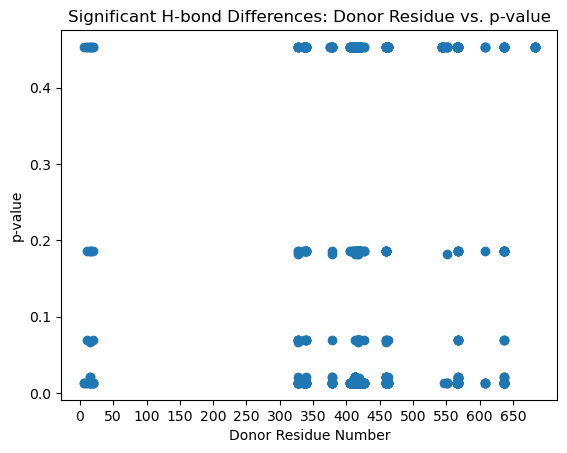

In [62]:
# Extract donor_res_num_adjusted from the multi-index
donor_res_nums = significant_diff.index.get_level_values('donor_res_num_adjusted')

# Plot donor_res_num_adjusted vs p_value
plt.plot(donor_res_nums, significant_diff['p_value'], 'o', label='Significant H-bonds')
# Set x-axis ticks every 5 residues
min_res = donor_res_nums.min()  # Minimum residue number
max_res = donor_res_nums.max()  # Maximum residue number
tick_locations = range(int(min_res // 50) * 50, int(max_res // 50) * 50 + 50, 50)  # Start at a multiple of 5, step by 5
plt.xticks(tick_locations)
plt.xlabel('Donor Residue Number')
plt.ylabel('p-value')
plt.title('Significant H-bond Differences: Donor Residue vs. p-value')
plt.show()

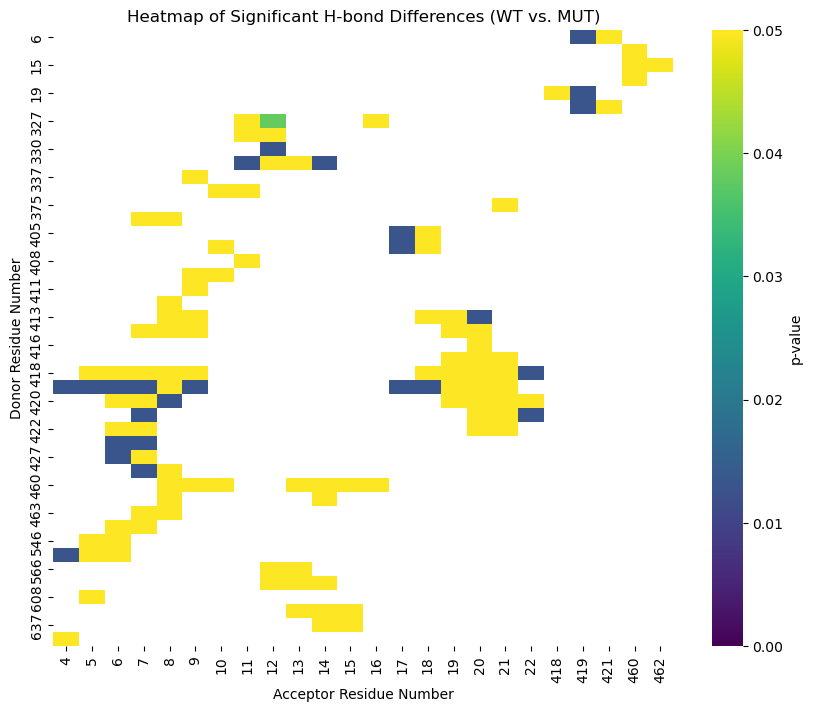

In [63]:
# Reset index to make donor_res_num_adjusted and acceptor_res_num_adjusted columns
significant_diff_reset = significant_diff.reset_index()

# Create a pivot table for the heatmap
heatmap_data = significant_diff_reset.pivot_table(
    index='donor_res_num_adjusted', 
    columns='acceptor_res_num_adjusted', 
    values='p_value', 
    #fill_value=1  # Use 1 (non-significant) for missing values
)

# Plot the heatmap
plt.figure(figsize=(10, 8))  # Adjust size as needed
sns.heatmap(
    heatmap_data, 
    cmap='viridis', 
    vmin=0, vmax=0.05,  # Focus on significant p-values 
    #annot=True, 
    fmt='.3f',  # Format annotations to 3 decimal places
    cbar_kws={'label': 'p-value'}  # Label the color bar
)

# Add labels and title
plt.xlabel('Acceptor Residue Number')
plt.ylabel('Donor Residue Number')
plt.title('Heatmap of Significant H-bond Differences (WT vs. MUT)')
plt.show()

In [64]:
significant_diff_reset[significant_diff_reset['donor_res_num_adjusted'] ==419].sort_values('p_value', ascending=False).head()

,donor,hydrogen,acceptor,donor_res_num_adjusted,acceptor_res_num_adjusted,WT_mean,WT_std,MUT,p_value
243,4746,4747,20156,419,20,83.75,167.5,0,0.453255
245,4746,4747,20158,419,20,45.50,91.0,0,0.453255
244,4746,4747,20157,419,20,0.25,0.5,0,0.453255
248,4756,4757,20132,419,19,0.50,1.0,0,0.453255
247,4756,4757,20124,419,19,1.00,2.0,0,0.453255


In [65]:
# Example: Combine WT and MUT data
wt_replicates = wt_dfs  
mut_replicate = mut_df 

# Add group and replicate columns
for i, df in enumerate(wt_replicates):
    df['group'] = 'WT'
    df['replicate'] = f'WT_{i+1}'

mut_replicate['group'] = 'MUT'
mut_replicate['replicate'] = 'MUT_1'

# Combine all data
combined_df = pd.concat(wt_replicates + [mut_replicate], ignore_index=True)

In [66]:
# Filter for residue 419
residue_419_df = combined_df[
    (combined_df['donor_res_num_adjusted'] == 419) | 
    (combined_df['acceptor_res_num_adjusted'] == 419)
]

In [67]:
from scipy.stats import ttest_ind, mannwhitneyu

# Separate WT and MUT data for residue 419
wt_419 = residue_419_df[residue_419_df['group'] == 'WT']
mut_419 = residue_419_df[residue_419_df['group'] == 'MUT']

# Perform statistical tests
t_stat, t_pval = ttest_ind(wt_419['count'], mut_419['count'], equal_var=False)
u_stat, u_pval = mannwhitneyu(wt_419['count'], mut_419['count'])

print(f"T-test p-value: {t_pval}")
print(f"Mann-Whitney U test p-value: {u_pval}")

T-test p-value: 0.08422664591088831
Mann-Whitney U test p-value: 0.18707070726036978


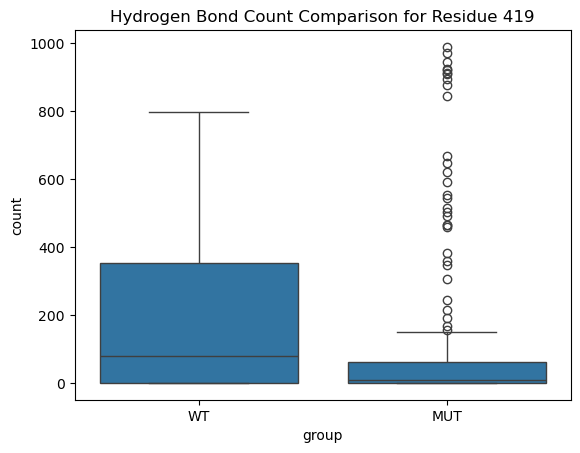

In [68]:
import seaborn as sns
import matplotlib.pyplot as plt


# Boxplot for residue 419
sns.boxplot(data=residue_419_df, x='group', y='count')
plt.title('Hydrogen Bond Count Comparison for Residue 419')
plt.show()

In [69]:
# Group by donor-acceptor pairs and compare
hbonds_summary = residue_419_df.groupby(['donor', 'acceptor', 'group'])['count'].mean().unstack()
print(hbonds_summary)# Group by residue and compare

group                 MUT     WT
donor acceptor                  
4746  19034      1.000000    NaN
      19036     27.000000    NaN
      20156           NaN  335.0
      20157           NaN    1.0
      20158           NaN  182.0
...                   ...    ...
19024 4765       9.000000    NaN
19437 14188      5.666667    NaN
20197 4759       3.500000    NaN
      4762      23.000000    NaN
      4765      25.000000    NaN

[95 rows x 2 columns]


In [70]:
residue_summary = combined_df.groupby(['donor_res_num_adjusted', 'group'])['count'].mean().unstack()
print(residue_summary)

group                          MUT          WT
donor_res_num_adjusted                        
6                        14.000000   64.500000
10                        2.000000    5.000000
15                        9.272727    8.272727
16                             NaN    3.333333
19                        5.666667    8.000000
20                       18.000000    1.000000
327                     313.769231  201.644444
328                     173.884615   54.800000
330                       4.000000         NaN
336                      62.346667   54.119048
337                            NaN  500.750000
340                     151.225000   93.714286
375                            NaN    2.333333
378                     202.125000  235.413043
405                       1.833333    3.000000
406                       2.000000    6.066667
408                       3.777778    1.000000
410                      22.724138   51.600000
411                            NaN  431.000000
412          